In [1]:
import numpy as np 
import os
import matplotlib.pyplot as plt 
import math
import mdtraj as md
import seaborn as sns

In [2]:
coord_mm = np.load('5003962_coords_lam0.npz')['coords']
coord_ml = np.load('5003962_coords_lam1.npz')['coords']

coord_mm_lig = coord_mm[:,:26,:]
coord_ml_lig = coord_ml[:,:26,:]

In [3]:
topology = md.Topology()
chain = topology.add_chain()
residue = topology.add_residue("res", chain)
for i in range(26):
    topology.add_atom(f"Atom{i}", element=md.element.carbon, residue=residue)

In [4]:
phi1_ind = [[6,8,13,14]]

phi1 = []
for molecule in coord_mm_lig:
    traj = md.Trajectory(molecule, topology)
    dihedrals_1 = md.compute_dihedrals(traj, phi1_ind)[0][0]
    phi1.append(dihedrals_1)
    
phi1_MM = np.degrees(phi1)

phi1 = []
for molecule in coord_ml_lig:
    traj = md.Trajectory(molecule, topology)
    dihedrals_1 = md.compute_dihedrals(traj, phi1_ind)[0][0]
    phi1.append(dihedrals_1)
    
phi1_ML = np.degrees(phi1)

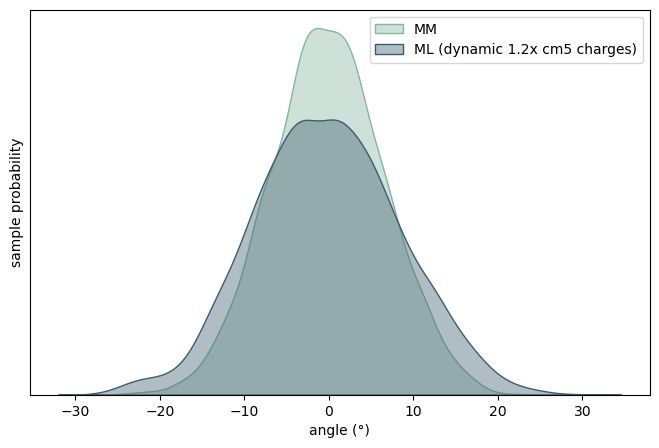

In [5]:
plt.figure(figsize=(8, 5))
sns.kdeplot(phi1_MM, fill=True, label="MM", color="#86b5a1", alpha=0.4)
sns.kdeplot(phi1_ML, fill=True, label="ML (dynamic 1.2x cm5 charges)", color="#3d5C6F", alpha=0.4)

plt.legend()
plt.xlabel('angle (°)')
plt.ylabel('sample probability')
plt.yticks([])
# plt.savefig('5003962_angle.svg',dpi = 300)
plt.show()